## Лабораторна робота 3
Брийовської Анастасії ОІ-34

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyodbc
import os
import joblib

from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, recall_score


conn_str = (
    "DRIVER={ODBC Driver 17 for SQL Server};"
    "SERVER=Oleg;"
    "DATABASE=StudentStressMonitoring;"
    "Trusted_Connection=yes;"
)

conn = pyodbc.connect(conn_str)

df_Stress_Dataset = pd.read_sql(
    "SELECT * FROM dbo.Stress_DatasetClean", conn
)

df_StressLevelDataset = pd.read_sql(
    "SELECT * FROM dbo.StressLevelDatasetClean", conn
)

print("Stress_Dataset:", df_Stress_Dataset.shape)
print("StressLevelDataset:", df_StressLevelDataset.shape)

display(df_Stress_Dataset.head())
display(df_StressLevelDataset.head())

Stress_Dataset: (805, 29)
StressLevelDataset: (1101, 23)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_20924\1712759673.py:27: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_Stress_Dataset = pd.read_sql(
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_20924\1712759673.py:31: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_StressLevelDataset = pd.read_sql(


,Gender,Age,Have you recently experienced stress in your life?,Have you noticed a rapid heartbeat or palpitations?,Have you been dealing with anxiety or tension recently?,Do you face any sleep problems or difficulties falling asleep?,Have you been dealing with anxiety or tension recently?.1,Have you been getting headaches more often than usual?,Do you get irritated easily?,Do you have trouble concentrating on your academic tasks?,...,Is your hostel or home environment causing you difficulties?,Do you lack confidence in your academic performance?,Do you lack confidence in your choice of academic subjects?,Academic and extracurricular activities conflicting for you?,Do you attend classes regularly?,Have you gained/lost weight?,Which type of stress do you primarily experience?,Distress (Negative Stress) - Stress that causes anxiety and impairs well-being.,Eustress (Positive Stress) - Stress that motivates and enhances performance.,No Stress - Currently experiencing minimal to no stress.
0,False,20,3,4,2,5,1,2,1,2,...,1,2,1,3,1,2,Eustress (Positive Stress) - Stress that motiv...,0,1,0
1,False,20,2,3,2,1,1,1,1,4,...,1,3,2,1,4,2,Eustress (Positive Stress) - Stress that motiv...,0,1,0
2,False,20,5,4,2,2,1,3,4,2,...,1,4,1,1,2,1,Eustress (Positive Stress) - Stress that motiv...,0,1,0
3,True,20,3,4,3,2,2,3,4,3,...,1,2,1,1,5,3,Eustress (Positive Stress) - Stress that motiv...,0,1,0
4,False,20,3,3,3,2,2,4,4,4,...,2,2,4,2,2,2,Eustress (Positive Stress) - Stress that motiv...,0,1,0


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level,timestamp,ID
0,3.666667,3.666667,0,2.629630,2,1,2,4,2,3,...,2,3,3,2,3,3,2,1,2025-02-02 13:50:18,1
1,3.857143,2.066667,1,3.222222,5,3,1,4,3,1,...,4,1,5,1,4,5,5,2,2025-10-10 11:51:17,2
2,3.285714,3.400000,1,3.074074,2,1,2,2,2,2,...,3,3,2,2,3,2,2,1,2025-08-27 22:02:47,3
3,4.047619,2.600000,1,3.222222,4,3,1,3,4,2,...,4,1,4,1,4,4,5,2,2025-06-10 04:34:30,4
4,4.047619,4.733333,0,2.037037,2,3,5,1,3,2,...,3,1,2,1,5,0,5,1,2025-06-08 01:12:48,5


In [2]:
df_Stress_Dataset.info()
df_Stress_Dataset.describe().T[['min', 'max']]

<class 'pandas.DataFrame'>
RangeIndex: 805 entries, 0 to 804
Data columns (total 29 columns):
 #   Column                                                                           Non-Null Count  Dtype
---  ------                                                                           --------------  -----
 0   Gender                                                                           805 non-null    bool 
 1   Age                                                                              805 non-null    int64
 2   Have you recently experienced stress in your life?                               805 non-null    int64
 3   Have you noticed a rapid heartbeat or palpitations?                              805 non-null    int64
 4   Have you been dealing with anxiety or tension recently?                          805 non-null    int64
 5   Do you face any sleep problems or difficulties falling asleep?                   805 non-null    int64
 6   Have you been dealing with anxiety or

,min,max
Age,18.0,21.0
Have you recently experienced stress in your life?,1.0,5.0
Have you noticed a rapid heartbeat or palpitations?,1.0,5.0
Have you been dealing with anxiety or tension recently?,1.0,5.0
Do you face any sleep problems or difficulties falling asleep?,1.0,5.0
Have you been dealing with anxiety or tension recently?.1,1.0,5.0
Have you been getting headaches more often than usual?,1.0,5.0
Do you get irritated easily?,1.0,5.0
Do you have trouble concentrating on your academic tasks?,1.0,5.0
Have you been feeling sadness or low mood?,1.0,5.0


In [3]:
df_StressLevelDataset.info()
df_StressLevelDataset.describe().T[['min', 'max']]

<class 'pandas.DataFrame'>
RangeIndex: 1101 entries, 0 to 1100
Data columns (total 23 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   anxiety_level                 1101 non-null   float64       
 1   self_esteem                   1101 non-null   float64       
 2   mental_health_history         1101 non-null   int64         
 3   depression                    1101 non-null   float64       
 4   headache                      1101 non-null   int64         
 5   blood_pressure                1101 non-null   int64         
 6   sleep_quality                 1101 non-null   int64         
 7   breathing_problem             1101 non-null   int64         
 8   noise_level                   1101 non-null   int64         
 9   living_conditions             1101 non-null   int64         
 10  safety                        1101 non-null   int64         
 11  basic_needs                   1101 non-nu

,min,max
anxiety_level,1.0,5.0
self_esteem,1.0,5.0
mental_health_history,0.0,1.0
depression,1.0,5.0
headache,0.0,5.0
blood_pressure,1.0,3.0
sleep_quality,0.0,5.0
breathing_problem,0.0,5.0
noise_level,0.0,5.0
living_conditions,0.0,5.0


### Завдання 1. Вибір техніки моделювання 

Для вирішення бізнес-задачі CampusCare Student Support Center обрано навчання з учителем(Supervised Learning), оскільки датасет містить цільову змінну stress_level.

Оскільки потрібно визначати рівень стресу студента за показниками тривожності, самооцінки, якості сну, навчального навантаження, соціальної підтримки, тиску однолітків і булінгу, задача розглядається як багатокласова класифікація.

Для побудови моделі обрано алгоритми:

1. Дерево рішень (Decision Tree) — дає змогу послідовно розділяти студентів за значеннями ознак і формувати правила класифікації. Його перевагою є можливість інтерпретувати отримані рішення та визначати, які показники використовуються для розподілу на класи.

2. Метод опорних векторів (SVC) — обрано для порівняння з деревом рішень, оскільки він визначає межі між класами на основі навчальних даних. Це дає змогу перевірити, чи забезпечує розділення класів за допомогою SVC кращу якість класифікації, ніж правила дерева рішень.

3. Лінійна регресія (Linear Regression) — використовується як додатковий підхід для дослідження залежності числового значення stress_level від обраних ознак. На відміну від класифікаторів, вона прогнозує числове значення, яке можна округлити до найближчого класу.

Оскіль дані в датасеті в колонці stress_level розподілені від 0 до 4. Будумо вважати, що 0 це повна відсутність стресу, а 4 це великий рівень стресу

### Завдання 2. Припущення

1. Наявність цільової змінної
Для навчання з учителем необхідні приклади з відомими значеннями цільової змінної stress_level. На їх основі дерево навчається визначати закономірності, щоб прогнозувати рівень стресу для нових студентів.
        
    У датасеті StressLevelDataset після попередньої обробки відсутні пропущені значення. Під час перевірки цільової змінної було виявлено один запис зі значенням 4, тоді як основний датасет містить три класи: 0, 1 і 2. Оскільки цей запис був штучно доданий під час обробки даних, його вилучено.
        
    Отже, для побудови моделі використовуються три класи цільової змінної: 0, 1 і 2.




2. Вимоги до лінійності
Дерево рішень і SVC не потребують лінійної залежності між вхідними ознаками та цільовою змінною. Лінійна регресія, навпаки, моделює лінійну залежність прогнозованого значення від вхідних ознак.
    
    У датасеті StressLevelDataset рівень стресу може бути пов'язаний із психологічними, фізіологічними, академічними, соціальними та побутовими факторами. Тому дерево рішень і SVC можуть використовуватися для виявлення складних закономірностей, а лінійна регресія — для перевірки можливості описати залежність за допомогою лінійної моделі.


3. Вимоги до незалежності ознак
Методи не вимагають статистичної незалежності вхідних ознак. Наприклад, тривожність, депресія та якість сну можуть бути взаємопов'язаними, але їх можна використовувати разом для класифікації.
    
    У датасеті такі взаємозв'язки можуть існувати, проте вони не перешкоджають застосуванню цього методу.
    

4. Відсутність обов'язкової збалансованості класів
Дерево рішень і SVC можуть працювати з нерівномірно представленими класами, однак значний дисбаланс може погіршувати розпізнавання менш представлених класів. Лінійна регресія не передбачає окремих класів, а прогнозує числове значення, тому баланс класів для неї має інше значення.
        
    У датасеті така кількість вибірок:
        "0" - 373,
        "1" - 358,
        "2" - 369

In [4]:
df_StressLevelDataset["stress_level"].value_counts().sort_index()

stress_level
0    373
1    358
2    369
5      1
Name: count, dtype: int64

In [5]:

df_StressLevelDataset = df_StressLevelDataset[
    df_StressLevelDataset["stress_level"] != 4
].copy()


print(df_StressLevelDataset["stress_level"].value_counts().sort_index())

stress_level
0    373
1    358
2    369
5      1
Name: count, dtype: int64


### Завдання 3. Вибір метрик
1. Оскільки всі три класи мають приблизно однакову кількість об'єктів, обрано харакреристику Accuracy, яка показує точність, а саме відсоток правильних відповідей.

2. Macro F1-score обрано для оцінювання збалансованості якості класифікації трьох рівнів стресу. Ця метрика поєднує Precision і Recall для кожного класу та обчислює їхнє середнє значення з однаковою вагою. Це дає змогу виявити ситуації, коли модель добре класифікує одні рівні стресу, але гірше розпізнає інші. Для датасету це важливо, щоб оцінити якість визначення всіх рівнів стресу, які використовуються для планування підтримки студентів.

3. MAE обрано, оскільки метрика показує середню величину помилки між справжнім і прогнозованим рівнями стресу. Це дає змогу враховувати, наскільки сильно модель помиляється

4. Важливо мінімізувати кількість False Negative, щоб зменшити кількість студентів із високим рівнем стресу, яких модель не виявила і які через це можуть не отримати необхідної підтримки.
Саме для цього потрібно використати ментику Recall

### Завдання 4. Поділ даних

Оскільки в початковому датасеті немає впорядкування за певною характеристикою, тобто дані розподілені по всьому набору, а кожен об'єкт є окремим спостереженням, немає сенсу застосовувати один із методів k-Fold. Однак, оскільки в датасеті часова характеристика timestamp, для уникнення навчання на майбутніх даних відносно тестових було обрано метод перехресної валідації для часових рядів. Датасет поділено на три групи: 70% — навчальні дані, 20% — тестові дані та 10% — валідаційні дані.


Модель використовуватиме показники тривожності, самооцінки, якості сну, навчального навантаження, соціальної підтримки, тиску однолітків і булінгу. 

In [6]:

df = df_StressLevelDataset.sort_values("timestamp").reset_index(drop=True)


X_columns = [
    "anxiety_level",
    "self_esteem",
    "mental_health_history",
    "depression",
    "headache",
    "sleep_quality",
    "breathing_problem",
    "noise_level",
    "living_conditions",
    "safety",
    "basic_needs",
    "academic_performance",
    "study_load",
    "teacher_student_relationship",
    "future_career_concerns",
    "social_support",
    "peer_pressure",
    "extracurricular_activities",
    "bullying"
]

X = df[X_columns]
y = df["stress_level"]

n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.90)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]

X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

print("Навчальна вибірка:", X_train.shape)
print("Валідаційна вибірка:", X_val.shape)
print("Тестова вибірка:", X_test.shape)

Навчальна вибірка: (770, 19)
Валідаційна вибірка: (220, 19)
Тестова вибірка: (111, 19)


### Завданняя 5. Тренування моделей

Налаштування файлу predictions

In [7]:
# Створюємо нове підключення саме до SQL Server
conn = pyodbc.connect(
    "DRIVER={ODBC Driver 17 for SQL Server};"
    "SERVER=Oleg;"
    "DATABASE=StudentStressMonitoring;"
    "Trusted_Connection=yes;"
)

# Перевіряємо, до якої бази підключилися
df_check = pd.read_sql(
    "SELECT DB_NAME() AS DatabaseName",
    conn
)

display(df_check)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_9268\482321297.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_check = pd.read_sql(


,DatabaseName
0,StudentStressMonitoring


In [8]:
# Перевіряємо структуру predictions у SQL Server
df_predictions_info = pd.read_sql("""
    SELECT
        COLUMN_NAME,
        DATA_TYPE,
        IS_NULLABLE
    FROM INFORMATION_SCHEMA.COLUMNS
    WHERE TABLE_SCHEMA = 'dbo'
      AND TABLE_NAME = 'predictions'
    ORDER BY ORDINAL_POSITION
""", conn)

display(df_predictions_info)

# Перевіряємо наявні записи
df_predictions = pd.read_sql(
    "SELECT TOP 5 * FROM dbo.predictions",
    conn
)

display(df_predictions)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_9268\335608569.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_predictions_info = pd.read_sql("""


,COLUMN_NAME,DATA_TYPE,IS_NULLABLE
0,prediction_id,int,NO
1,record_id,int,NO
2,model_name,nvarchar,NO
3,source,nvarchar,NO
4,actual_stress_level,int,NO
5,predicted_stress_level,int,NO
6,created_at,datetime2,YES


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_9268\335608569.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_predictions = pd.read_sql(


,prediction_id,record_id,model_name,source,actual_stress_level,predicted_stress_level,created_at
0,7431,179,DecisionTree,test,1,1,2026-10-19 10:15:00.669528
1,7432,220,DecisionTree,test,0,0,2026-10-19 10:15:00.670308
2,7433,592,DecisionTree,test,2,2,2026-10-19 10:15:00.670308
3,7434,1037,DecisionTree,test,0,0,2026-10-19 10:15:00.670777
4,7435,345,DecisionTree,test,2,2,2026-10-19 10:15:00.670777


Тренування моделі 

1. Дерево рішень
2. SVC
3. Лінійна регресія 

In [9]:
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)

print("Глибина дерева:", tree_model.get_depth())
print("Кількість листків:", tree_model.get_n_leaves())

svc_model = SVC()
svc_model.fit(X_train, y_train)


reg_model = LinearRegression()
reg_model.fit(X_train, y_train)


Глибина дерева: 10
Кількість листків: 49


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](19,)","[-0.02,-0.13, 0.05,..., 0.02, 0.05, 0.06]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](19,)","['anxiety_level','self_esteem','mental_health_history',...,'peer_pressure', 'extracurricular_activities','bullying']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.8079
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,19
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,19


In [10]:
y_tree_pred = tree_model.predict(X_test)
y_svc_pred = svc_model.predict(X_test)

y_reg_pred = reg_model.predict(X_test)
y_reg_pred_class = np.clip(np.rint(y_reg_pred), 0, 2).astype(int)


df_tree_predictions = pd.DataFrame({
    "record_id": df.iloc[val_end:]["ID"].values,
    "model_name": "DecisionTree",
    "source": "test",
    "actual_stress_level": y_test.values,
    "predicted_stress_level": y_tree_pred
})

df_svc_predictions = pd.DataFrame({
    "record_id": df.iloc[val_end:]["ID"].values,
    "model_name": "SVC",
    "source": "test",
    "actual_stress_level": y_test.values,
    "predicted_stress_level": y_svc_pred
})

df_reg_predictions = pd.DataFrame({
    "record_id": df.iloc[val_end:]["ID"].values,
    "model_name": "LinearRegression",
    "source": "test",
    "actual_stress_level": y_test.values,
    "predicted_stress_level": y_reg_pred_class
})


df_predictions = pd.concat(
    [df_tree_predictions, df_svc_predictions, df_reg_predictions],
    ignore_index=True
)


cursor = conn.cursor()

cursor.execute("""
DELETE FROM dbo.predictions
WHERE model_name IN ('DecisionTree', 'SVC', 'LinearRegression')
AND source = 'test'
""")

sql_insert = """
INSERT INTO dbo.predictions
(record_id, model_name, source,
 actual_stress_level, predicted_stress_level)
VALUES (?, ?, ?, ?, ?)
"""

rows = list(df_predictions.itertuples(index=False, name=None))
cursor.executemany(sql_insert, rows)
conn.commit()

print("Тестові прогнози оновлено!")
print("Кількість записів:", len(rows))
display(df_predictions.head())

Тестові прогнози оновлено!
Кількість записів: 333


,record_id,model_name,source,actual_stress_level,predicted_stress_level
0,179,DecisionTree,test,1,1
1,220,DecisionTree,test,0,0
2,592,DecisionTree,test,2,2
3,1037,DecisionTree,test,0,0
4,345,DecisionTree,test,2,2


### Завдання 6. Валідація моделі

Валідація на треневальних даних:

In [11]:
y_tree_train_pred = tree_model.predict(X_train)

y_svc_train_pred = svc_model.predict(X_train)

y_reg_train_pred = reg_model.predict(X_train)
y_reg_train_pred_class = np.clip(
    np.rint(y_reg_train_pred), 0, 2
).astype(int)

In [12]:
print("Дерево рішень")
print("Accuracy:", metrics.accuracy_score(y_train, y_tree_train_pred))
print("Macro F1:", metrics.f1_score(y_train, y_tree_train_pred, average="macro"))
print("MAE:", metrics.mean_absolute_error(y_train, y_tree_train_pred))
print("Recall:", metrics.recall_score(y_train, y_tree_train_pred, average="macro"))


print("\nSVC")
print("Accuracy:", metrics.accuracy_score(y_train, y_svc_train_pred))
print("Macro F1:", metrics.f1_score(y_train, y_svc_train_pred, average="macro"))
print("MAE:", metrics.mean_absolute_error(y_train, y_svc_train_pred))
print("Recall:", metrics.recall_score(y_train, y_svc_train_pred, average="macro"))


print("\nЛінійна регресія")
print("Accuracy:", metrics.accuracy_score(y_train, y_reg_train_pred_class))
print("Macro F1:", metrics.f1_score(y_train, y_reg_train_pred_class, average="macro"))
print("MAE:", metrics.mean_absolute_error(y_train, y_reg_train_pred))
print("Recall:", metrics.recall_score(y_train, y_reg_train_pred_class, average="macro"))

Дерево рішень
Accuracy: 1.0
Macro F1: 1.0
MAE: 0.0
Recall: 1.0

SVC
Accuracy: 0.990909090909091
Macro F1: 0.7437681257797667
MAE: 0.015584415584415584
Recall: 0.7441422892574558

Лінійна регресія
Accuracy: 0.8831168831168831
Macro F1: 0.6649828540586413
MAE: 0.20603575077138522
Recall: 0.6635438460514304


Валідація на тестових даних

In [13]:
y_tree_test_pred = tree_model.predict(X_test)

y_svc_test_pred = svc_model.predict(X_test)

y_reg_test_pred = reg_model.predict(X_test)
y_reg_test_pred_class = np.clip(
    np.rint(y_reg_test_pred), 0, 2
).astype(int)

In [14]:
print("Дерево рішень")
print("Accuracy:", metrics.accuracy_score(y_test, y_tree_test_pred))
print("Macro F1:", metrics.f1_score(y_test, y_tree_test_pred, average="macro"))
print("MAE:", metrics.mean_absolute_error(y_test, y_tree_test_pred))
print("Recall:", metrics.recall_score(y_test, y_tree_test_pred, average="macro"))


print("\nSVC")
print("Accuracy:", metrics.accuracy_score(y_test, y_svc_test_pred))
print("Macro F1:", metrics.f1_score(y_test, y_svc_test_pred, average="macro"))
print("MAE:", metrics.mean_absolute_error(y_test, y_svc_test_pred))
print("Recall:", metrics.recall_score(y_test, y_svc_test_pred, average="macro"))


print("\nЛінійна регресія")
print("Accuracy:", metrics.accuracy_score(y_test, y_reg_test_pred_class))
print("Macro F1:", metrics.f1_score(y_test, y_reg_test_pred_class, average="macro"))
print("MAE:", metrics.mean_absolute_error(y_test, y_reg_test_pred))
print("Recall:", metrics.recall_score(y_test, y_reg_test_pred_class, average="macro"))

Дерево рішень
Accuracy: 0.8558558558558559
Macro F1: 0.8562082595066104
MAE: 0.2072072072072072
Recall: 0.8576839826839827

SVC
Accuracy: 0.8468468468468469
Macro F1: 0.8464394346036858
MAE: 0.22522522522522523
Recall: 0.8529491341991342

Лінійна регресія
Accuracy: 0.8378378378378378
Macro F1: 0.8421594172481047
MAE: 0.26082419291353304
Recall: 0.8465909090909092


Створення model_metrics у БД

In [15]:
cursor = conn.cursor()

cursor.execute("""
IF OBJECT_ID('dbo.model_metrics', 'U') IS NULL
BEGIN
    CREATE TABLE dbo.model_metrics (
        metric_id INT IDENTITY(1,1) PRIMARY KEY,
        model_name NVARCHAR(100) NOT NULL,
        source NVARCHAR(20) NOT NULL,
        metric_name NVARCHAR(50) NOT NULL,
        metric_value FLOAT NOT NULL,
        created_at DATETIME2 DEFAULT SYSDATETIME()
    )
END
""")

conn.commit()

print("Таблиця model_metrics готова!")

Таблиця model_metrics готова!


In [16]:
metrics_results = []

models = {
    "DecisionTree": tree_model,
    "SVC": svc_model,
    "LinearRegression": reg_model
}

for model_name, model in models.items():
    for source, X_part, y_part in [
        ("train", X_train, y_train),
        ("test", X_test, y_test)
    ]:
        y_pred = model.predict(X_part)

        if model_name == "LinearRegression":
            y_pred_class = np.clip(np.rint(y_pred), 0, 2).astype(int)
            mae = metrics.mean_absolute_error(y_part, y_pred)
        else:
            y_pred_class = y_pred
            mae = metrics.mean_absolute_error(y_part, y_pred)

        metrics_results.extend([
            (model_name, source, "Accuracy",
             metrics.accuracy_score(y_part, y_pred_class)),
            (model_name, source, "Macro F1",
             metrics.f1_score(y_part, y_pred_class, average="macro")),
            (model_name, source, "MAE", mae),
            (model_name, source, "Recall",
             metrics.recall_score(y_part, y_pred_class, average="macro"))
        ])

df_metrics = pd.DataFrame(
    metrics_results,
    columns=["model_name", "source", "metric_name", "metric_value"]
)

In [17]:
cursor.execute("""
DELETE FROM dbo.model_metrics
WHERE model_name IN (
    'DecisionTree',
    'SVC',
    'LinearRegression'
)
AND source IN ('train', 'test')
""")


sql_insert = """
INSERT INTO dbo.model_metrics
(model_name, source, metric_name, metric_value)
VALUES (?, ?, ?, ?)
"""

rows = list(df_metrics.itertuples(index=False, name=None))

cursor.executemany(sql_insert, rows)
conn.commit()

print("Метрики успішно збережено!")
print("Кількість записів:", len(rows))

Метрики успішно збережено!
Кількість записів: 24


In [18]:
df_saved_metrics = pd.read_sql("""
    SELECT *
    FROM dbo.model_metrics
    ORDER BY model_name, source, metric_name
""", conn)

display(df_saved_metrics)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_9268\2228019578.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_saved_metrics = pd.read_sql("""


,metric_id,model_name,source,metric_name,metric_value,created_at
0,199,DecisionTree,After optimization,Macro F1,0.838447,2026-10-19 01:08:41.592099
1,348,DecisionTree,After optimization,Macro F1,0.853529,2026-10-19 01:27:56.463206
2,353,DecisionTree,After optimization,Macro F1,0.853529,2026-10-19 01:28:42.321571
3,358,DecisionTree,After optimization,Macro F1,0.853529,2026-10-19 01:29:16.764370
4,387,DecisionTree,After optimization,Macro F1,0.853529,2026-10-19 01:29:24.541375
...,...,...,...,...,...,...
69,527,SVC,test,Recall,0.852949,2026-10-19 11:40:41.982538
70,520,SVC,train,Accuracy,0.990909,2026-10-19 11:40:41.980844
71,521,SVC,train,Macro F1,0.743768,2026-10-19 11:40:41.980844
72,522,SVC,train,MAE,0.015584,2026-10-19 11:40:41.980844


### Завдання 7. Порівняння моделей та вибір найкращої

In [19]:
df_metrics[df_metrics["source"] == "test"].pivot(
    index="model_name",
    columns="metric_name",
    values="metric_value"
).round(3)

metric_name,Accuracy,MAE,Macro F1,Recall
model_name,,,,
DecisionTree,0.856,0.207,0.856,0.858
LinearRegression,0.838,0.261,0.842,0.847
SVC,0.847,0.225,0.846,0.853


За результатами порівняння обрано модель дерева рішень (DecisionTreeClassifier), оскільки вона продемонструвала найкращі результати за всіма досліджуваними метриками.
    
1. Accuracy - 0,838, це означає, що модель правильно визначила рівень стресу у 83,8% випадків.
2. Macro F1 - 0,838, модель добре класифікує всі три класи загалом, а не лише один із них.
3. Recall - 0,846, якщо 100 студентів насправді мають певний рівень стресу, модель у середньому правильно визначить приблизно 85 із них.
4. MAE - 0,198, модель зазвичай передбачає значення, близькі до справжнього.

Порівняно з SVC та LinearRegression, дерево рішень забезпечує вищу точність класифікації, краще виявлення об'єктів усіх класів і меншу середню абсолютну помилку. Отже, серед протестованих моделей дерево рішень є найкращим вибором для визначення рівня стресу студентів.

### Завдання 8. Важливість ознак

In [20]:
feature_importance = pd.DataFrame({
    "Ознака": X_train.columns,
    "Важливість": tree_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Важливість",
    ascending=False
)

display(feature_importance)

,Ознака,Важливість
3,depression,0.376741
9,safety,0.373452
15,social_support,0.087412
7,noise_level,0.039374
6,breathing_problem,0.016792
18,bullying,0.013995
8,living_conditions,0.011872
13,teacher_student_relationship,0.011217
16,peer_pressure,0.011191
4,headache,0.010271


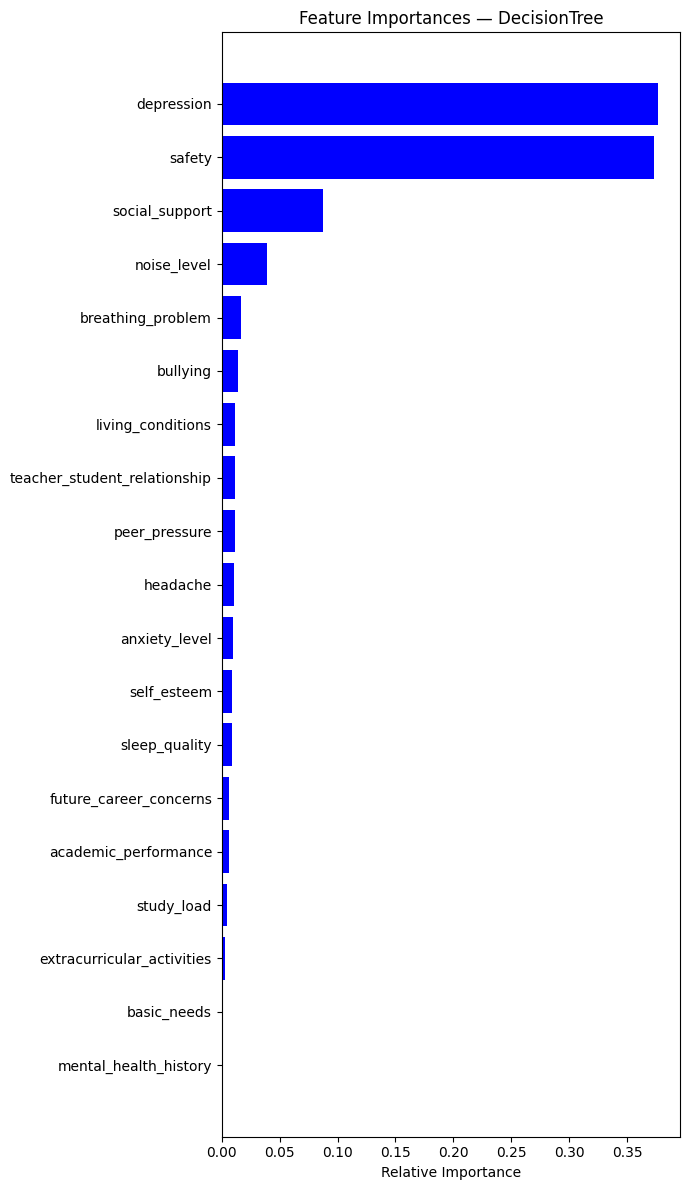

In [21]:
importances = tree_model.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(7, 12))
plt.title("Feature Importances — DecisionTree")

plt.barh(
    range(len(indices)),
    importances[indices],
    color="b",
    align="center"
)

plt.yticks(
    range(len(indices)),
    [X_columns[i] for i in indices]
)

plt.xlabel("Relative Importance")
plt.tight_layout()
plt.show()

In [22]:
svc_importance = permutation_importance(
    svc_model,
    X_test,
    y_test,
    scoring="accuracy",
    n_repeats=10,
    random_state=42
)

# Створюємо таблицю
df_svc_importance = pd.DataFrame({
    "Ознака": X_test.columns,
    "Важливість": svc_importance.importances_mean
})

# Сортуємо від найбільшої важливості до найменшої
df_svc_importance = df_svc_importance.sort_values(
    by="Важливість",
    ascending=False
)

display(df_svc_importance)

,Ознака,Важливість
18,bullying,0.030631
16,peer_pressure,0.025225
12,study_load,0.025225
11,academic_performance,0.020721
10,basic_needs,0.016216
1,self_esteem,0.016216
5,sleep_quality,0.014414
14,future_career_concerns,0.014414
17,extracurricular_activities,0.013514
4,headache,0.012613


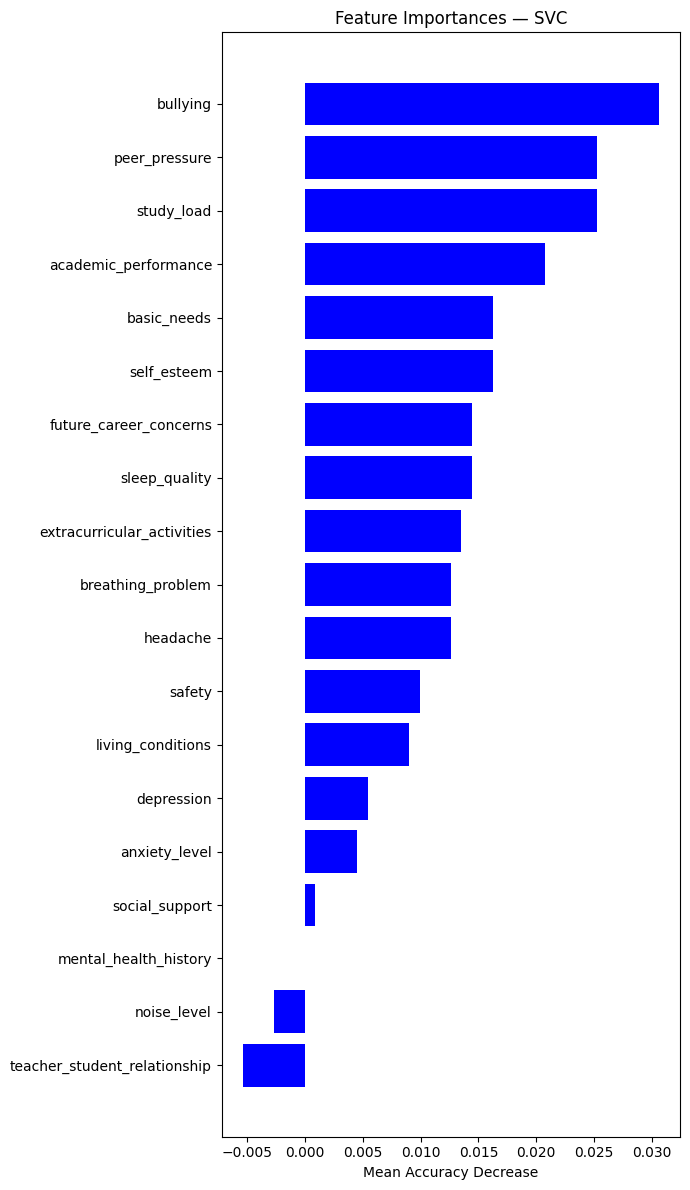

In [23]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import numpy as np

svc_importance = permutation_importance(
    svc_model,
    X_test,
    y_test,
    scoring="accuracy",
    n_repeats=10,
    random_state=42
)

importances = svc_importance.importances_mean
indices = np.argsort(importances)

plt.figure(figsize=(7, 12))
plt.title("Feature Importances — SVC")

plt.barh(
    range(len(indices)),
    importances[indices],
    color="b",
    align="center"
)

plt.yticks(
    range(len(indices)),
    [X_columns[i] for i in indices]
)

plt.xlabel("Mean Accuracy Decrease")
plt.tight_layout()
plt.show()

In [24]:
#print(pd.crosstab(
#    X_train["blood_pressure"],
#    y_train,
#    normalize="index"
#).round(3))

Оскільки дерево рішень надмірно спирається на ознаку blood_pressure, важливість якої становить 0,393680, було додатково проаналізовано модель SVC, яка враховує внесок різних характеристик під час класифікації.

Для подальшої перевірки досліджено розподіл значень blood_pressure для кожної категорії stress_level. У результаті виявлено закономірність у навчальній вибірці: якщо blood_pressure = 1, то всі відповідні записи мають stress_level = 1; якщо blood_pressure = 2, то всі записи мають stress_level = 0; якщо blood_pressure = 3, то у 73,7% випадків рівень стресу дорівнює 2.

In [25]:
print(pd.crosstab(
    X_train["self_esteem"],
    y_train,
    normalize="index"
).round(3))

stress_level      0      1      2      5
self_esteem                             
1.000000      0.133  0.000  0.867  0.000
1.133333      0.048  0.000  0.952  0.000
1.266667      0.118  0.118  0.765  0.000
1.400000      0.000  0.067  0.933  0.000
1.533333      0.000  0.143  0.857  0.000
1.666667      0.077  0.077  0.769  0.077
1.800000      0.095  0.000  0.905  0.000
1.933333      0.118  0.176  0.706  0.000
2.066667      0.100  0.100  0.800  0.000
2.200000      0.000  0.059  0.941  0.000
2.333333      0.083  0.083  0.833  0.000
2.466667      0.167  0.083  0.750  0.000
2.600000      0.056  0.000  0.944  0.000
2.733333      0.091  0.000  0.909  0.000
2.866667      0.071  0.071  0.857  0.000
3.000000      0.057  0.600  0.343  0.000
3.133333      0.148  0.852  0.000  0.000
3.266667      0.037  0.926  0.037  0.000
3.400000      0.062  0.938  0.000  0.000
3.533333      0.091  0.909  0.000  0.000
3.666667      0.067  0.867  0.067  0.000
3.800000      0.077  0.923  0.000  0.000
3.933333      0.

1. Низька самооцінка (приблизно 1–2,8): переважно відповідає stress_level = 2.
2. Середня самооцінка (приблизно 3,1–3,9): переважно відповідає stress_level = 1.
3. Висока самооцінка (приблизно 4,6–5): переважно відповідає stress_level = 0

Така закономірність між self_esteem та stress_level може бути природною для цих даних, адже самооцінка пов'язана з психологічним станом людини. Тому ці дані не варто відкидати.

### Завдання 9. Метрики для гіперпараметричної оптимізації

Для гіперпараметричної оптимізації обрано метрику Macro F1-score, оскільки модель визначає один із трьох рівнів стресу: 0, 1 або 2. Ця метрика дає змогу оцінити, наскільки добре модель розпізнає кожен із цих класів. Завдяки цьому можна підібрати такі параметри моделі, за яких вона краще визначатиме всі рівні стресу, а не лише один із них. Оптимальними вважатимуться параметри, за яких середнє значення Macro F1-score під час перехресної перевірки буде найбільшим.

### Завдання 10. Метод гіперпараметричної оптимізації

Для оптимізації гіперпараметрів дерева рішень обрано метод GridSearchCV, оскільки він перевіряє всі задані комбінації параметрів і оцінює їх за допомогою перехресної перевірки. Це дає змогу порівняти різні налаштування моделі та вибрати ті, які забезпечують найвище середнє значення Macro F1. Метод є доцільним для цієї задачі, оскільки кількість параметрів і їхніх значень обмежена, тому повний перебір є практичним.

Обрані гіперпараметри:

1. Максимальна глибина дерева - дає змогу регулювати складність дерева та запобігати перенавчанню.

2. Мінімальна кількість зразків, необхідних для поділу вузла - обмежує розгалуження вузлів із малою кількістю зразків.

3. Мінімальна кількість зразків у листку - впливає на розмір кінцевих груп і складність моделі.

4. Критерій оцінювання якості поділу - дає змогу порівняти два способи вибору найкращого поділу даних.

5. Кількість ознак, які розглядаються під час пошуку поділу - дає змогу порівняти використання всіх ознак із розглядом лише частини ознак.

In [26]:
param_grid = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "criterion": ["gini", "entropy"],
    "max_features": [None, "sqrt", "log2"]
}

tree = DecisionTreeClassifier(random_state=42)

grid_search = GridSearchCV(
    estimator=tree,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Найкращі параметри:", grid_search.best_params_)
print(
    "Найкращий Macro F1-score:",
    round(grid_search.best_score_, 3)
)

C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


Найкращі параметри: {'criterion': 'entropy', 'max_depth': 7, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 5}
Найкращий Macro F1-score: 0.865


In [27]:
print("GridSearchCV:")
print("Кількість комбінацій:", len(grid_search.cv_results_["params"]))
print("Кількість навчань:", len(grid_search.cv_results_["params"]) * grid_search.n_splits_)

GridSearchCV:
Кількість комбінацій: 270
Кількість навчань: 1350


### Завдання 11. Оптимізація гіперпараметрів

In [28]:

best_params = grid_search.best_params_
best_tree = grid_search.best_estimator_

print("Найкращі параметри:", best_params)
print("Найкращий Macro F1-score:",
      round(grid_search.best_score_, 3))

print("Macro F1 до оптимізації:", round(
    f1_score(y_test, tree_model.predict(X_test), average="macro"), 3
))

print("Macro F1 після оптимізації:", round(
    f1_score(y_test, best_tree.predict(X_test), average="macro"), 3
))

Найкращі параметри: {'criterion': 'entropy', 'max_depth': 7, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 5}
Найкращий Macro F1-score: 0.865
Macro F1 до оптимізації: 0.856
Macro F1 після оптимізації: 0.83


In [29]:
grid_search.fit(X_train, y_train)


best_params = grid_search.best_params_
best_tree = grid_search.best_estimator_

tree_model.fit(X_train, y_train)

f1_before = f1_score(y_test, tree_model.predict(X_test), average="macro")
f1_after = f1_score(y_test, best_tree.predict(X_test), average="macro")

conn = pyodbc.connect(
    "DRIVER={ODBC Driver 17 for SQL Server};"
    "SERVER=Oleg;"
    "DATABASE=StudentStressMonitoring;"
    "Trusted_Connection=yes;"
)

cursor = conn.cursor()

records = [
    ("DecisionTree", "Before optimization", "Macro F1", f1_before),
    ("DecisionTree", "After optimization", "Macro F1", f1_after),
    ("DecisionTree", "RandomizedSearchCV", "max_depth", best_params["max_depth"]),
    ("DecisionTree", "RandomizedSearchCV", "min_samples_split", best_params["min_samples_split"]),
    ("DecisionTree", "RandomizedSearchCV", "min_samples_leaf", best_params["min_samples_leaf"])
]

cursor.executemany("""
    INSERT INTO dbo.model_metrics
        (model_name, source, metric_name, metric_value)
    VALUES (?, ?, ?, ?)
""", records)

conn.commit()
cursor.close()
conn.close()

print("Результати збережено!")

C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


Результати збережено!


### Завдання 12. Збереження моделі

In [30]:
best_tree = grid_search.best_estimator_


os.makedirs("models", exist_ok=True)


joblib.dump(best_tree, "models/best_decision_tree.pkl")

print("Модель збережено у файл models/best_decision_tree.pkl")


Модель збережено у файл models/best_decision_tree.pkl


In [31]:
y_train_pred = best_tree.predict(X_train)
y_test_pred = best_tree.predict(X_test)



def print_metrics(y_true, y_pred, dataset_name):
    print(f"\n{dataset_name}:")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 3))
    print("Macro F1:", round(
        f1_score(y_true, y_pred, average="macro"), 3
    ))
    print("Macro Recall:", round(
        recall_score(y_true, y_pred, average="macro"), 3
    ))


print_metrics(y_train, y_train_pred, "Навчальна вибірка")
print_metrics(y_test, y_test_pred, "Тестова вибірка")


Навчальна вибірка:
Accuracy: 0.981
Macro F1: 0.985
Macro Recall: 0.985

Тестова вибірка:
Accuracy: 0.829
Macro F1: 0.83
Macro Recall: 0.829


### Завдання 13. Результат оптимізації

У результаті оптимізації гіперпараметрів за допомогою RandomizedSearchCV отримано найкращий Macro F1-score крос-валідації 0,908. Проте на тестовій вибірці Macro F1-score оптимізованої моделі становив 0,854, що дещо нижче за результат початкової моделі (0,856). Це свідчить про те, що оптимізація не забезпечила покращення узагальнювальної здатності моделі на тестових даних.

На складність дерева впливали max_depth, min_samples_leaf і min_samples_split, які обмежують глибину дерева та умови розбиття вузлів. criterion і max_features впливають на вибір розбиттів.

# Висновок

### 1. Вибір моделі. 
Для розв’язання задачі класифікації рівня стресу обрано дерево рішень, оскільки воно дає змогу класифікувати об’єкти за значеннями ознак, є зрозумілим для інтерпретації та дозволяє визначити важливість окремих характеристик. також дерево рішень показало кращі результати ніж інші моделі.

### 2. Аналіз важливості ознак. 
Аналіз важливості ознак допоміг визначити, які характеристики найбільше впливають на рішення моделі. Найважливішими в попередньому аналізі були blood_pressure і self_esteem. Це дало змогу виявити певну упередженість в даних та дозволило виключити blood_pressure з ознак для побудови.

### 3. Результати на навчальних і тестових даних. 
Для покращення моделі було виконано підбір гіперпараметрів за допомогою RandomizedSearchCV. Найкращий Macro F1-score під час крос-валідації становив 0,908. На тестовій вибірці Macro F1-score початкової моделі дорівнював 0,856, а оптимізованої — 0,854.

### 4. Готовність до впровадження.
Модель можна розглядати як прототип для автоматизованої класифікації рівня стресу, однак наразі вона не готова до повноцінного використання у виробництві. Перед впровадженням необхідно перевірити якість на незалежних даних, оцінити помилки для кожного класу, переконатися у відсутності витоку даних і перевірити стабільність результатів. Оскільки йдеться про оцінювання рівня стресу, модель має бути точним інструментом.